# Week 9 - Combining Models

Learning contents:
- Base Classifier
    - Train a Least Squares classifier, perform a prediction on the samples, and compute the accuracy
    - Plot the decision boundary for least squares classifier
- Committees
    - Split the training data into M=9 equally sized, non-overlapping parts
    - Train M=9 Least Squares classifiers, one for each data split
    - Perform predictions on the whole dataset using a committee of classifiers and compute the accuracy
    - Plot the decision boundary for committee classifier
- Decision tree
    - Fit a DecisionTreeClassifier using scikit-learn, perform a prediction on the data, and compute the accuracy
    - Plot the decision boundary for the DecisionTreeClassifier
- AdaBoost
    - Create an AdaBoost classifier of DecisionTreeClassifiers using the scikit-learn library
    - Plot the decision boundary for the AdaBoostClassifier


In [83]:
# Dependencies
import numpy as np
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA 
import matplotlib.pyplot as plt 
import seaborn as sns; sns.set_theme(); sns.set_palette('bright')

In [84]:
# Some plotting functions, we'll be using later
from matplotlib.colors import ListedColormap

class_cmap = ListedColormap(["#0072B2", "#E69F00"])


def plot_scatter(data, target, alpha=0.5, legend=True):
    scatter = plt.scatter(data[:, 0], data[:, 1], c=target, edgecolor='none', alpha=alpha, cmap=class_cmap, vmin=0, vmax=1)
    if legend:
        plt.legend(*scatter.legend_elements(), loc="upper right", title="Targets")
    plt.xlabel('Component 1')
    plt.ylabel('Component 2')
    
def plot_mesh(X, pred_fn, n_class=2):
    plt_margin = 5
    x_min, x_max = min(X[:,0]) - plt_margin, max(X[:,0]) + plt_margin
    y_min, y_max = min(X[:,1]) - plt_margin, max(X[:,1]) + plt_margin
    h = 0.1  # step size in the mesh
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = pred_fn(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    cs = plt.contourf(xx, yy, Z, alpha = 0.1, cmap=class_cmap, levels=[-0.5, 0.5, 1.5], vmin=0, vmax=1)

# Dataset
We'll be working with a slightly modified version of the digits data

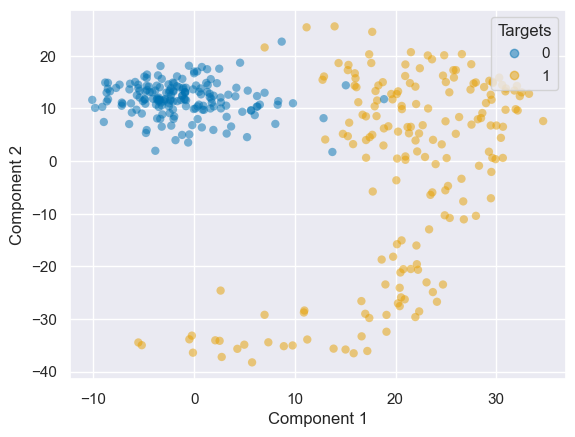

In [85]:
digits = load_digits(n_class=2)

# Get a 2D version of the data using PCA
pca = PCA(n_components=2)
t = digits.target
X = pca.fit_transform(digits.data)

# In order to get a non-linearly seperable case, 
# we'll modify the data a bit this time, 
# translating the class-0 points to the right and up
X = np.where(
    np.repeat(np.expand_dims(t == 1, axis=1), 2, axis=1), 
    X, 
    np.vstack([X[:,0]+20, X[:,1]+10]).T
)

N = len(t) # total number of samples

plot_scatter(X, t)

# 0) Base Classifier

## 0.1) Train a Least Squares classifier, perform a prediction on the samples, and compute the accuracy
Implement a Least Squares classifier using the same mathematical method as in Week 7 section 1.1–1.2 (augment X with a column of ones, compute pseudo-inverse solution). A class-based wrapper `LeastSquaresClassifier` is provided as a scaffold below — fill in the three methods, then train the classifier, predict on the full dataset, and print the accuracy as a single float.

The accuracy is the proportion of correct predictions.

*Expected accuracy: approx. 0.97*

In [86]:
class LeastSquaresClassifier():
    @staticmethod
    def phi(X):
        """Augment with bias: phi_0(x) = 1. Input X: (N, 2) -> output: (N, 3)."""
        # TODO: return X augmented with a column of ones (same as Week 7 augment())
        N = X.shape[0]
        aux = np.ones((N, 1))
        res = np.hstack((aux, X))
        return res

    def fit(self, X, y):
        """Compute self.W from training data. X: (N, 2), y: (N,)."""
        # TODO: compute W using the pseudo-inverse (same math as Week 7 section 1.1)
        X_tilde = self.phi(X)
        self.W = np.linalg.pinv(X_tilde) @ y
        return self.W

    def predict(self, X):
        """Return raw discriminant values y = W @ phi(X).T (NOT binarized). X: (N, 2) -> (N,)."""
        # TODO
        return self.W @ self.phi(X).T

# TODO: train the classifier, predict on the full dataset, and print the accuracy as a single float

model = LeastSquaresClassifier()
fit = model.fit(X = X, y = t)
scores = model.predict(X = X)
predictions = scores >= 0.5
accuracy = np.mean(predictions == t)
print(float(accuracy))


0.9694444444444444


## 0.2) Plot the decision boundary for least squares classifier
Hint: you can do this by either plotting a line on the boundary or creating a mesh of all predictions (similar to section 1.3 in "week 7 - Linear classification"). You can of course use the helper functions (plot_scatter() and plot_mesh()) given at the start of this file. 

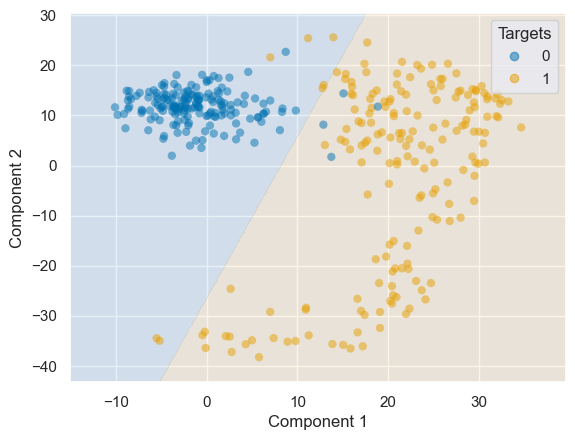

In [87]:
plt.figure()
plot_mesh(X, lambda points: model.predict(points) >= 0.5)
plot_scatter(X, t)
plt.show()


# 1) Committees

## 1.1) Split the training data into M=9 equally sized, non-overlapping parts
Hint: use the numpy.split() command.

In [88]:
M = 9
parts = np.array_split(X, M)
#print(parts)
target_parts = np.array_split(t, M)

## 1.2) Train M=9 Least Squares classifiers, one for each (9) data split using the same method as in section 0.1
Hint: loop over the training data containing of the X split and t split zipped together using the zip() command.

In [89]:

models = []

for X_part, t_part in zip(parts, target_parts):
    model_aux = LeastSquaresClassifier()
    model_aux.fit(X_part, t_part)
    models.append(model_aux)

## 1.3) Perform a prediction on the whole dataset using committee of classifiers (see the 'Committees' slide in Lecture 17, frame 9) and compute the accuracy

*Expected: approx. 0.96 (note: the committee may underperform the single LS classifier on this dataset — why?)*

R = why? Well, each committee member trains on fewer samples, and averaging linear scores still produces a linear boundary. The committee therefore cannot capture a more complex boundary, and averaging does not guarantee better accuracy.

In [90]:
all_scores = np.array([model.predict(X) for model in models]) # Shape (9, N)

committee_scores = np.mean(all_scores, axis=0) # Average across classifiers: one score per sample

predictions = committee_scores >= 0.5
accuracy = np.mean(predictions == t)
print(float(accuracy))

0.9583333333333334


## 1.4 Plot the decision boundary for committee classifier

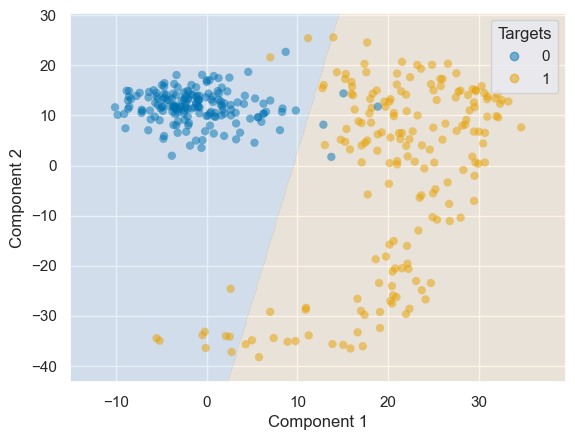

In [91]:
def committee_predict(points):
    scores = np.array([model.predict(points) for model in models])
    return np.mean(scores, axis=0) >= 0.5

plt.figure()
plot_mesh(X, committee_predict)
plot_scatter(X, t)
plt.show()


_Note: Committees (Section 1) and AdaBoost (Section 3) are covered in Lecture 17. Decision trees (Section 2) are covered in Lecture 18, the second lecture of Week 9._

# 2) Tree

## 2.1) Fit a DecisionTreeClassifier imported from the `scikit-learn` library, perform a prediction on the data, and compute the accuracy
Use `max_depth=3` and `random_state=42`. You will use fit() and predict() methods of the DecisionTreeClassifier class in order to respectively train and predict from your classifier

*Expected accuracy: approx. 0.99*

In [92]:
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X = X, y = t)
predicts = tree.predict(X = X)
accuracy = np.mean(predicts == t)
print(float(accuracy))

0.9861111111111112


## 2.2) Plot the decision boundary for the DecisionTreeClassifier

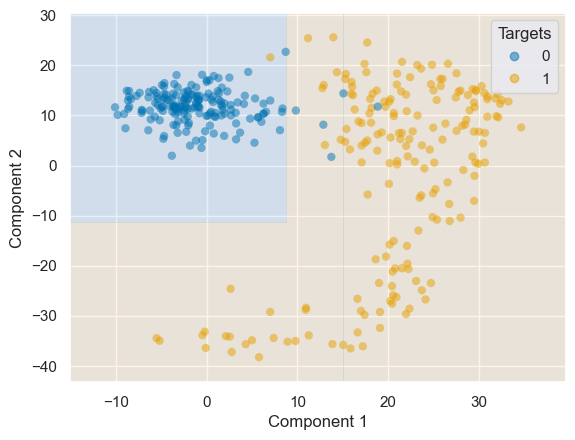

In [93]:
plt.figure()
plot_mesh(X, tree.predict)
plot_scatter(X, t)
plt.show()

# 3) AdaBoost

## 3.1) Create an AdaBoost classifier of DecisionTreeClassifiers using the `scikit-learn` library, and compute the accuracy
Use a depth of 1 for the `DecisionTreeClassifier` and 7 estimators for the `AdaBoostClassifier`. Use `random_state=42` and defaults for all remaining parameters.

*Expected accuracy: approx. 0.98*

In [94]:
from sklearn.ensemble import AdaBoostClassifier
stump = DecisionTreeClassifier(max_depth=1, random_state=42)
ada = AdaBoostClassifier(estimator=stump, n_estimators=7, random_state=42)
ada.fit(X=X, y = t)
pred = ada.predict(X = X)
accuracy = np.mean(pred == t)
print(float(accuracy))

0.9777777777777777


## 3.2) Plot the decision boundary for the AdaBoostClassifier

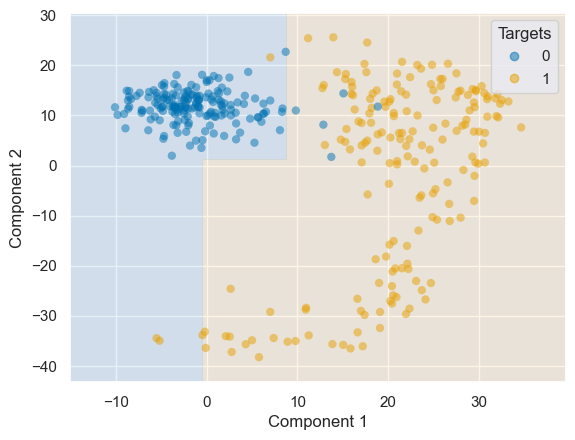

In [95]:
plt.figure()
plot_mesh(X, ada.predict)
plot_scatter(X, t)
plt.show()